# Brecha Digital en Argentina (EPH - INDEC)
**Práctica Profesional I**

En este notebook analizamos si el **ingreso**, el **nivel educativo** y la **región** influyen en que un hogar tenga **Internet** y **computadora**.

Cada celda hace una sola cosa y debajo se ve el resultado.

## Librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

## 1. Cargar los datos
Leemos el archivo CSV. Usamos `sep=";"` porque las columnas están separadas por punto y coma.

In [2]:
df = pd.read_csv("../DATA/eph_tecnologia_microdatos.csv", sep=";")
df.head()

,CODUSU,REGION,IX_TOT,NIVEL_ED,ITF,DECIFR,IV12_3,II7
0,HOG_EPH_2026_0001,40,3,3,198127.28,1,1.0,1
1,HOG_EPH_2026_0002,44,6,4,NaN,6,1.0,2
2,HOG_EPH_2026_0003,42,5,4,1392730.43,9,1.0,1
3,HOG_EPH_2026_0004,41,4,4,420184.85,3,2.0,2
4,HOG_EPH_2026_0005,1,2,2,108507.59,1,2.0,1


Cantidad de filas (hogares) y columnas:

In [3]:
df.shape

(1000, 8)

Cantidad de valores vacíos en cada columna:

In [4]:
df.isnull().sum()

CODUSU       0
REGION       0
IX_TOT       0
NIVEL_ED     0
ITF         53
DECIFR       0
IV12_3      36
II7          0
dtype: int64

## 2. Limpieza de los datos
El código **9** significa "no sabe / no responde". Lo cambiamos por vacío para que no se cuente como un dato real.

In [5]:
df["NIVEL_ED"] = df["NIVEL_ED"].replace(9, None)
df["II7"] = df["II7"].replace(9, None)
df["IV12_3"] = df["IV12_3"].replace(9, None)

Eliminamos los hogares que no tienen ingreso (ITF vacío):

In [6]:
df = df.dropna(subset=["ITF"])
print("Hogares que quedan:", len(df))

Hogares que quedan: 947


Calculamos el **ingreso per cápita familiar (IPCF)**: el ingreso del hogar dividido por la cantidad de personas.

In [7]:
df["IPCF"] = df["ITF"] / df["IX_TOT"]
df[["ITF", "IX_TOT", "IPCF"]].head()

,ITF,IX_TOT,IPCF
0,198127.28,3,66042.426667
2,1392730.43,5,278546.086000
3,420184.85,4,105046.212500
4,108507.59,2,54253.795000
5,1874973.06,6,312495.510000


Cambiamos los números por nombres para que se entiendan mejor:

In [8]:
df["REGION_NOMBRE"] = df["REGION"].map({1: "GBA", 40: "NOA", 41: "NEA", 42: "Cuyo", 43: "Pampeana", 44: "Patagonia"})

df["NIVEL_EDUCATIVO"] = df["NIVEL_ED"].map({1: "1. Primario incompleto", 2: "2. Primario completo",
                                            3: "3. Secundario incompleto", 4: "4. Secundario completo",
                                            5: "5. Superior"})

df["INTERNET"] = df["II7"].map({1: "Sí", 2: "No"})
df["COMPUTADORA"] = df["IV12_3"].map({1: "Sí", 2: "No"})

df[["REGION_NOMBRE", "NIVEL_EDUCATIVO", "INTERNET", "COMPUTADORA"]].head()

,REGION_NOMBRE,NIVEL_EDUCATIVO,INTERNET,COMPUTADORA
0,NOA,3. Secundario incompleto,Sí,Sí
2,Cuyo,4. Secundario completo,Sí,Sí
3,NEA,4. Secundario completo,No,No
4,GBA,2. Primario completo,Sí,No
5,GBA,5. Superior,NaN,Sí


Dividimos los hogares en **5 grupos de ingreso (quintiles)**: Q1 es el 20% más pobre y Q5 el 20% más rico.

In [9]:
df["QUINTIL"] = pd.qcut(df["IPCF"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
df["QUINTIL"].value_counts().sort_index()

QUINTIL
Q1    190
Q2    189
Q3    189
Q4    189
Q5    190
Name: count, dtype: int64

## 3. Análisis descriptivo

Estadísticas del ingreso per cápita (el 50% es la mediana):

In [10]:
df["IPCF"].describe()

count    9.470000e+02
mean     3.015238e+05
std      3.160256e+05
min      1.718163e+04
25%      1.199185e+05
50%      2.032159e+05
75%      3.521749e+05
max      3.634762e+06
Name: IPCF, dtype: float64

In [11]:
print("Media:", round(df["IPCF"].mean()))
print("Mediana:", round(df["IPCF"].median()))

Media: 301524
Mediana: 203216


La media es mucho más alta que la mediana porque hay pocos hogares con ingresos muy altos.

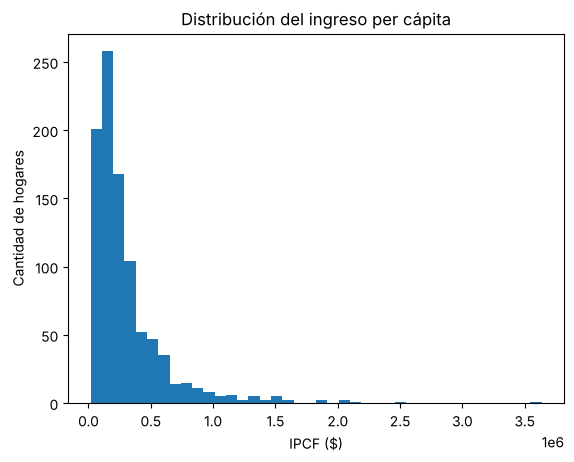

In [12]:
plt.hist(df["IPCF"], bins=40)
plt.title("Distribución del ingreso per cápita")
plt.xlabel("IPCF ($)")
plt.ylabel("Cantidad de hogares")
plt.show()

Porcentaje de hogares con Internet:

In [13]:
df["INTERNET"].value_counts(normalize=True) * 100

INTERNET
Sí    73.712446
No    26.287554
Name: proportion, dtype: float64

Porcentaje de hogares con computadora:

In [14]:
df["COMPUTADORA"].value_counts(normalize=True) * 100

COMPUTADORA
Sí    64.079823
No    35.920177
Name: proportion, dtype: float64

## 4. Hipótesis 1: ¿el ingreso influye en el acceso?
Hacemos una **tabla cruzada**: para cada quintil, qué porcentaje tiene y no tiene Internet.

In [15]:
pd.crosstab(df["QUINTIL"], df["INTERNET"], normalize="index") * 100

INTERNET,No,Sí
QUINTIL,,
Q1,40.957447,59.042553
Q2,35.869565,64.130435
Q3,23.404255,76.595745
Q4,19.892473,80.107527
Q5,11.290323,88.709677


Aplicamos el **test de chi-cuadrado**. Si el p-valor es menor a 0,05, la relación es significativa.

In [16]:
tabla = pd.crosstab(df["QUINTIL"], df["INTERNET"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 55.92
p-valor: 2.0843058368820432e-11


El p-valor aparece como `2.08e-11`. La `e-11` significa que es un número muy chico: 0,0000000000208. Es mucho menor a 0,05, así que **hay relación**.

Lo mismo con la computadora:

In [17]:
pd.crosstab(df["QUINTIL"], df["COMPUTADORA"], normalize="index") * 100

COMPUTADORA,No,Sí
QUINTIL,,
Q1,51.933702,48.066298
Q2,43.575419,56.424581
Q3,37.569061,62.430939
Q4,29.834254,70.165746
Q5,16.666667,83.333333


In [18]:
tabla = pd.crosstab(df["QUINTIL"], df["COMPUTADORA"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 56.84
p-valor: 1.3382752020548708e-11


Media y mediana del ingreso según si el hogar tiene Internet o computadora:

In [19]:
df.groupby("INTERNET")["IPCF"].agg(["mean", "median"])

,mean,median
INTERNET,,
No,205138.880540,143305.080000
Sí,335620.242392,228531.181667


In [20]:
df.groupby("COMPUTADORA")["IPCF"].agg(["mean", "median"])

,mean,median
COMPUTADORA,,
No,207826.505891,158543.706
Sí,354075.016930,240838.281


Gráfico de barras por quintil:

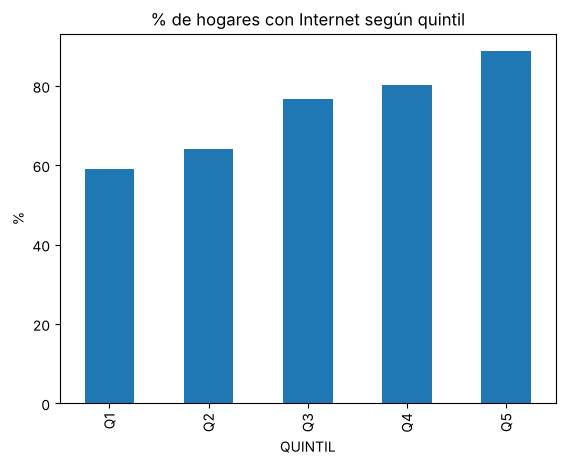

In [21]:
tabla_pct = pd.crosstab(df["QUINTIL"], df["INTERNET"], normalize="index") * 100
tabla_pct["Sí"].plot(kind="bar")
plt.title("% de hogares con Internet según quintil")
plt.ylabel("%")
plt.show()

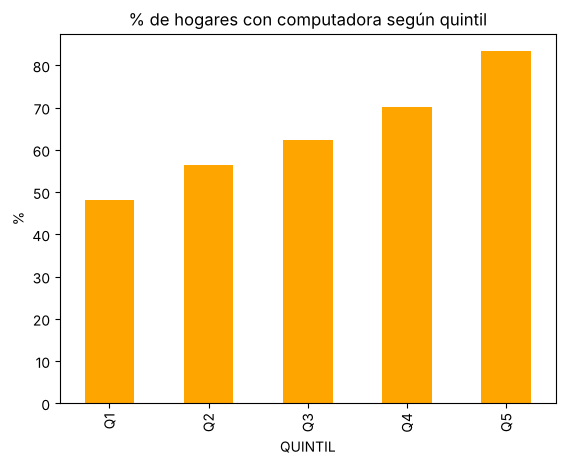

In [22]:
tabla_pct = pd.crosstab(df["QUINTIL"], df["COMPUTADORA"], normalize="index") * 100
tabla_pct["Sí"].plot(kind="bar", color="orange")
plt.title("% de hogares con computadora según quintil")
plt.ylabel("%")
plt.show()

Gráfico de torta: computadora en el quintil más pobre (Q1) y en el más rico (Q5):

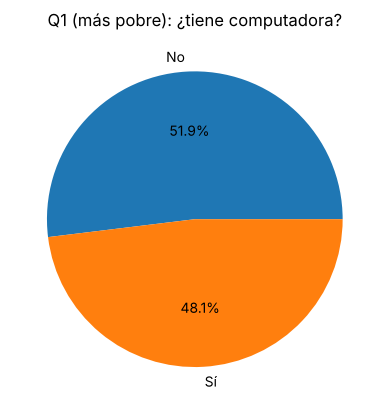

In [23]:
q1 = df[df["QUINTIL"] == "Q1"]["COMPUTADORA"].value_counts()
plt.pie(q1, labels=q1.index, autopct="%1.1f%%")
plt.title("Q1 (más pobre): ¿tiene computadora?")
plt.show()

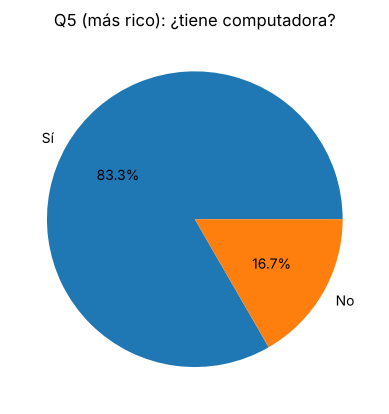

In [24]:
q5 = df[df["QUINTIL"] == "Q5"]["COMPUTADORA"].value_counts()
plt.pie(q5, labels=q5.index, autopct="%1.1f%%")
plt.title("Q5 (más rico): ¿tiene computadora?")
plt.show()

**Conclusión:** a más ingreso, más acceso. El p-valor es menor a 0,05, así que **la hipótesis 1 se cumple**.

## 5. Hipótesis 2: ¿la educación influye en el acceso?

In [25]:
pd.crosstab(df["NIVEL_EDUCATIVO"], df["INTERNET"], normalize="index") * 100

INTERNET,No,Sí
NIVEL_EDUCATIVO,,
1. Primario incompleto,56.578947,43.421053
2. Primario completo,38.235294,61.764706
3. Secundario incompleto,28.666667,71.333333
4. Secundario completo,14.218009,85.781991
5. Superior,1.600000,98.400000


In [26]:
tabla = pd.crosstab(df["NIVEL_EDUCATIVO"], df["INTERNET"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 107.57
p-valor: 2.397640948738065e-22


In [27]:
pd.crosstab(df["NIVEL_EDUCATIVO"], df["COMPUTADORA"], normalize="index") * 100

COMPUTADORA,No,Sí
NIVEL_EDUCATIVO,,
1. Primario incompleto,68.055556,31.944444
2. Primario completo,49.751244,50.248756
3. Secundario incompleto,36.896552,63.103448
4. Secundario completo,23.880597,76.119403
5. Superior,8.943089,91.056911


In [28]:
tabla = pd.crosstab(df["NIVEL_EDUCATIVO"], df["COMPUTADORA"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 101.12
p-valor: 5.673044607066315e-21


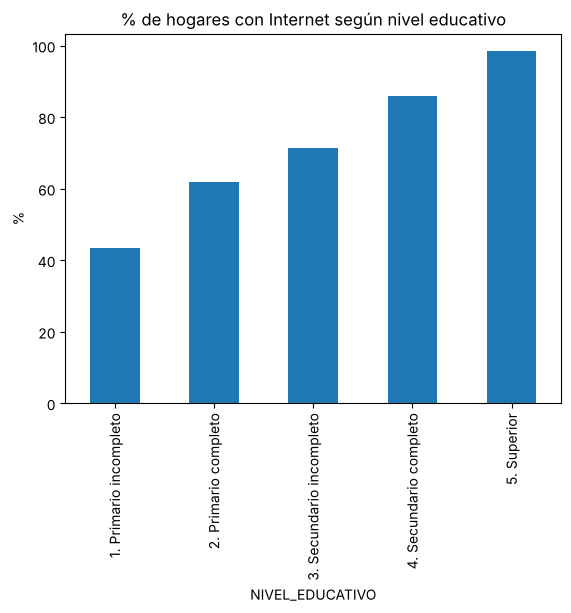

In [29]:
tabla_pct = pd.crosstab(df["NIVEL_EDUCATIVO"], df["INTERNET"], normalize="index") * 100
tabla_pct["Sí"].plot(kind="bar")
plt.title("% de hogares con Internet según nivel educativo")
plt.ylabel("%")
plt.show()

**Conclusión:** cuanto más alto el nivel educativo, más acceso. Es la variable con el chi-cuadrado más alto. **La hipótesis 2 se cumple**.

## 6. Hipótesis 3: ¿la región influye en el acceso?

In [30]:
pd.crosstab(df["REGION_NOMBRE"], df["INTERNET"], normalize="index") * 100

INTERNET,No,Sí
REGION_NOMBRE,,
Cuyo,27.848101,72.151899
GBA,24.477612,75.522388
NEA,28.930818,71.069182
NOA,27.131783,72.868217
Pampeana,25.547445,74.452555
Patagonia,26.881720,73.118280


In [31]:
tabla = pd.crosstab(df["REGION_NOMBRE"], df["INTERNET"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 1.34
p-valor: 0.9305447709124521


In [32]:
pd.crosstab(df["REGION_NOMBRE"], df["COMPUTADORA"], normalize="index") * 100

COMPUTADORA,No,Sí
REGION_NOMBRE,,
Cuyo,39.240506,60.759494
GBA,36.085627,63.914373
NEA,34.210526,65.789474
NOA,37.903226,62.096774
Pampeana,32.812500,67.187500
Patagonia,36.956522,63.043478


In [33]:
tabla = pd.crosstab(df["REGION_NOMBRE"], df["COMPUTADORA"])
chi2, p, gl, esperado = chi2_contingency(tabla)
print("Chi-cuadrado:", round(chi2, 2))
print("p-valor:", p)

Chi-cuadrado: 1.37
p-valor: 0.9278753700507606


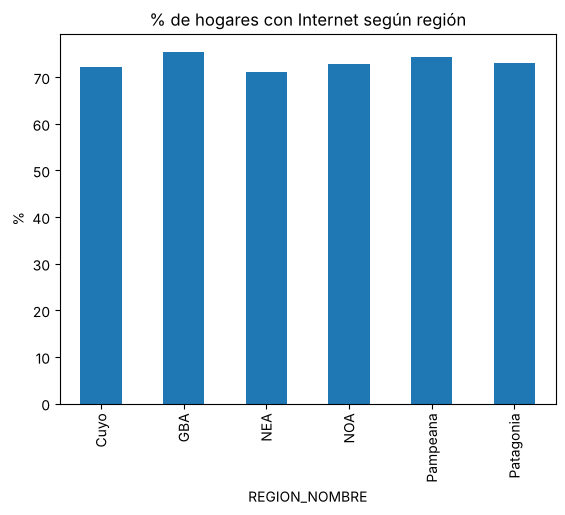

In [34]:
tabla_pct = pd.crosstab(df["REGION_NOMBRE"], df["INTERNET"], normalize="index") * 100
tabla_pct["Sí"].plot(kind="bar")
plt.title("% de hogares con Internet según región")
plt.ylabel("%")
plt.show()

**Conclusión:** todas las regiones tienen porcentajes parecidos y el p-valor es mayor a 0,05. **La hipótesis 3 no se cumple**.

## Conclusiones
- **Hipótesis 1 (ingreso):** se cumple.
- **Hipótesis 2 (educación):** se cumple, y es la que más diferencia marca.
- **Hipótesis 3 (región):** no se cumple.